# Proyecto Final Integrador · Fase 4 — Semana 3: Visualización, Consolidación y Comunicación de Resultados
- **Curso:** MCDI500 — Programación para la Ciencia de Datos (Grupo 3)
- **Docente:** Dr. Omar Iván Salinas Silva
- **Integrantes:** Victoria Álvarez, Ignacio Peña y Raúl Hormazábal

---

Este cuaderno cierra el proyecto transversal integrando las cuatro fases (**F1 → F2 → F3 → F4**). Siguiendo el principio de consolidación visto en clases, **la Fase 4 no vuelve a limpiar ni a transformar los datos**: recibe exclusivamente los **cuatro artefactos formales que entregó la Fase 3** (`entrenamiento_f3.csv`, `prueba_f3.csv`, `diccionario_f3.csv` y `parametros_f3.csv`), construye a partir de ellos una **copia interpretable con las unidades físicas y categorías originales**, verifica su fidelidad contra el archivo crudo y responde con visualizaciones explicativas la pregunta y los tres objetivos específicos declarados en la Fase 1.

| Fase | Cuaderno Ejecutable | Artefacto / Entregable que aporta a la siguiente fase |
| :---: | :--- | :--- |
| **F1** | `F1/notebooks/F1_Definicion.ipynb` | Problema acotado de persistencia, 3 objetivos específicos (`OE1`, `OE2`, `OE3`), alcance/restricciones/supuestos y diagnóstico de las 21 variables RETC. |
| **F2** | `F2/notebooks/F2_Preprocesamiento.ipynb` | Depuración de duplicados y nulos en `cantidad_kg`, rescate geográfico 2024 y matriz limpia (`118.141 × 61`). |
| **F3** | `F3/notebooks/F3_NucleoAlgoritmico_POO.ipynb` | Jerarquía POO (`Transformador(ABC)`, `Pipeline`, `Strategy`, `Observer`), `pytest` (`tests/`) y los 4 artefactos en `F2/data/processed/`. |
| **F4** | `F4/notebooks/F4_Visualizacion_Comunicacion.ipynb` | Copia interpretable (`src/comunicacion.py`), figuras explicativas en `F4/figuras/`, control de confusión y `F4/docs/hallazgos_f4.csv`. |

In [1]:
import json
import os
import sys
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from IPython.display import display

SEMILLA = 42
np.random.seed(SEMILLA)

# Posicionar el directorio de trabajo en la raíz del repositorio usando rutas relativas
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent.parent)
elif Path.cwd().name in {"F1", "F2", "F3", "F4"}:
    os.chdir(Path.cwd().parent)
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

from src import (
    COLUMNAS_ESPERADAS_RETC,
    MAPA_REGIONES_CHILE,
    cargar_datos_seguro,
    medir_tiempo_y_memoria,
    cargar_artefactos,
    leer_parametros,
    revertir_escalamiento,
    reconstruir_categorias,
    copia_interpretable,
    intervalo_wilson,
    tasa_por_grupo,
    guardar_figura,
)

# Paleta institucional con función preatentiva: el GRANATE señala el hallazgo, AZUL y GRIS dan el contexto
GRANATE = "#AC212E"
AZUL = "#06304A"
TINTA = "#0A1526"
HIELO = "#D7E3EE"
GRIS = "#8A94A0"
FUENTE_PIE = "Fuente: elaboración propia a partir de registros públicos RETC–SIDREP 2023–2025 (Ministerio del Medio Ambiente de Chile)."

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 12.0,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10.5,
    "axes.labelcolor": TINTA,
    "axes.edgecolor": GRIS,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

print("Python activo         :", sys.version.split()[0])
print("Entorno virtual activo:", sys.prefix != sys.base_prefix)
print(f"Librerías científicas : pandas {pd.__version__} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")
print("Raíz del repositorio  : ./ (verificada)")

Python activo         : 3.14.10
Entorno virtual activo: True
Librerías científicas : pandas 3.0.6 | NumPy 2.5.4 | Matplotlib 3.11.2 | seaborn 0.13.2
Raíz del repositorio  : ./ (verificada)


## 2. Carga de los Cuatro Artefactos de la Fase 3 y Verificación del Contrato
La función `cargar_artefactos("F2/data/processed")` de `src/comunicacion.py` lee los cuatro archivos generados por el `Pipeline` orientado a objetos de la Fase 3:
1. `entrenamiento_f3.csv` (`94.512 filas × 61 columnas`): subconjunto de ajuste (80 %).
2. `prueba_f3.csv` (`23.629 filas × 61 columnas`): subconjunto de prueba (20 %) transformado sin fuga de datos.
3. `diccionario_f3.csv` (`61 columnas`): esquema formal y tipos de datos de salida.
4. `parametros_f3.csv` (`3 pasos`): estadísticos aprendidos por `ImputadorPorGrupo`, `CodificadorCategorias` y `EscaladorRobusto`.

Antes de construir cualquier tabla o gráfico, se comprueba mediante aserciones (`assert`) que el contrato prometido por la Fase 3 se cumple íntegramente.

In [2]:
DIR_PROCESADO = Path("F2/data/processed")
DIR_FIGURAS = Path("F4/figuras")
DIR_DOCS_F4 = Path("F4/docs")

artefactos = cargar_artefactos(DIR_PROCESADO)
entrenamiento = artefactos["entrenamiento"]
prueba = artefactos["prueba"]
diccionario = artefactos["diccionario"]
parametros = leer_parametros(artefactos["parametros"])

for nombre, tabla in artefactos.items():
    print(f" - Artefacto '{nombre:<14}': {tabla.shape[0]:>7,} filas × {tabla.shape[1]:>2} columnas")

# Verificación formal del contrato de Fase 3 con assert
assert list(entrenamiento.columns) == list(diccionario["columna"]), "El entrenamiento no sigue el orden del diccionario F3."
assert list(prueba.columns) == list(entrenamiento.columns), "Entrenamiento y prueba difieren en su esquema de columnas."
assert int(entrenamiento.isna().sum().sum()) == 0 and int(prueba.isna().sum().sum()) == 0, "Existen valores nulos no resueltos."
assert np.isclose(entrenamiento["cantidad_kg_rob"].median(), 0.0, atol=1e-6), "La mediana escalada en entrenamiento debe ser 0.0."
q75_tr, q25_tr = entrenamiento["cantidad_kg_rob"].quantile(0.75), entrenamiento["cantidad_kg_rob"].quantile(0.25)
assert np.isclose(q75_tr - q25_tr, 1.0, atol=1e-4), "El RIC escalado en entrenamiento debe ser 1.0."

print("[OK] Contrato de Fase 3 verificado: esquemas idénticos (61 cols), 0 nulos, mediana=0.0 y RIC=1.0 en entrenamiento.")

 - Artefacto 'entrenamiento ':  94,512 filas × 61 columnas
 - Artefacto 'prueba        ':  23,629 filas × 61 columnas
 - Artefacto 'diccionario   ':      61 filas ×  3 columnas
 - Artefacto 'parametros    ':       3 filas ×  3 columnas
[OK] Contrato de Fase 3 verificado: esquemas idénticos (61 cols), 0 nulos, mediana=0.0 y RIC=1.0 en entrenamiento.


## 3. Construcción de la Copia Interpretable y Verificación Independiente contra el Archivo Original
El conjunto que entrega el `Pipeline` de la Fase 3 está optimizado para el modelamiento numérico (`61` columnas con variables continuas expresadas en rangos intercuartílicos y variables categóricas expandidas en indicadores `0/1`), pero **no sirve para la lectura humana en un gráfico**.

Por ello, `copia_interpretable(df, parametros)` realiza dos operaciones inversas exactas usando los parámetros guardados por la Fase 3:
1. **Reversión del escalamiento robusto:** recupera la magnitud física original despejando $x = x_{\text{rob}} \cdot \text{RIC}_{\text{train}} + \text{Mediana}_{\text{train}}$.
2. **Reconstrucción de variables categóricas:** reúne las columnas indicadoras `0/1` de `region` (16), `estado_materia` (4) y `comuna_agrupada` (11) en sus etiquetas legibles originales, verificando que cada fila tenga exactamente una categoría activa.

**La verificación que más rinde (no circular):** Comparamos la copia interpretable (`118.141` filas) directamente contra el archivo original `F1/data/raw/Base_Maestra_2023_2025.xlsx` mediante `np.allclose`, comprobando además con `timeit` y `tracemalloc` la eficiencia de la reversión vectorizada frente a una reversión fila por fila.

In [3]:
# Construcción de la copia interpretable 100 % a partir de los artefactos de Fase 3 (sin reprocesar datos)
entrenamiento_legible = copia_interpretable(entrenamiento, parametros)
prueba_legible = copia_interpretable(prueba, parametros)
legible = pd.concat([entrenamiento_legible, prueba_legible], ignore_index=True)

# Verificación independiente contra el archivo original de datos crudos (sin ejecutar funciones de F2/F3)
df_orig_crudo = cargar_datos_seguro("F1/data/raw/Base_Maestra_2023_2025.xlsx", columnas_esperadas=COLUMNAS_ESPERADAS_RETC)
df_orig_valido = df_orig_crudo.drop_duplicates().dropna(subset=["cantidad_kg"]).copy()
regiones_orig = df_orig_valido["region"].astype(str).str.strip().replace(MAPA_REGIONES_CHILE)
estados_orig = df_orig_valido["estado_materia"].astype(str).str.strip().str.lower()

comprobaciones_independientes = {
    "1. Mismo número total de declaraciones válidas (118.141)": len(legible) == len(df_orig_valido),
    "2. Masa cantidad_kg revertida idéntica al original (np.allclose)": bool(
        np.allclose(np.sort(legible["cantidad_kg_revertida"]), np.sort(df_orig_valido["cantidad_kg"]))
    ),
    "3. Conteo por región reconstruida desde One-Hot idéntico al original": (
        legible["region"].value_counts().to_dict() == regiones_orig.value_counts().to_dict()
    ),
    "4. Conteo por estado_materia reconstruido desde One-Hot idéntico al original": (
        legible["estado_materia"].value_counts().to_dict() == estados_orig.value_counts().to_dict()
    ),
}
for desc, ok in comprobaciones_independientes.items():
    assert ok, f"Falló la comprobación independiente: {desc}"
    print(f"[OK] {desc}: {ok}")

# Medición de eficiencia en Fase 4: Reversión vectorizada vs Reversión fila por fila (sobre las 5 variables escaladas)
def revertir_fila_a_fila(df_in: pd.DataFrame, params: dict) -> pd.DataFrame:
    res = df_in.copy()
    for col, info in params["EscaladorRobusto"].items():
        med, ric = float(info["mediana"]), float(info["ric"])
        res[f"{col}_revertida"] = [z * ric + med for z in res[f"{col}_rob"]]
    return res

m_fila = medir_tiempo_y_memoria(lambda: revertir_fila_a_fila(entrenamiento, parametros), repeticiones=5)
m_vec = medir_tiempo_y_memoria(lambda: revertir_escalamiento(entrenamiento, parametros), repeticiones=5)
pd.testing.assert_frame_equal(m_fila["resultado"], m_vec["resultado"])
speedup_f4 = round(m_fila["tiempo_min_s"] / max(m_vec["tiempo_min_s"], 1e-9), 1)
print(
    f"[OK] Eficiencia en reversión F4 (N={len(entrenamiento):,}, 5 vars): "
    f"Fila a fila = {m_fila['tiempo_min_s']:.5f} s ({m_fila['memoria_pico_mb']:.2f} MB) vs "
    f"Vectorizada = {m_vec['tiempo_min_s']:.5f} s ({m_vec['memoria_pico_mb']:.2f} MB) -> {speedup_f4}× más rápida"
)

display(legible[["año", "id_vu", "region", "rubro_nombre", "estado_materia", "cantidad_kg_revertida", "trayectoria_vu"]].head())

[OK] 1. Mismo número total de declaraciones válidas (118.141): True
[OK] 2. Masa cantidad_kg revertida idéntica al original (np.allclose): True
[OK] 3. Conteo por región reconstruida desde One-Hot idéntico al original: True
[OK] 4. Conteo por estado_materia reconstruido desde One-Hot idéntico al original: True


[OK] Eficiencia en reversión F4 (N=94,512, 5 vars): Fila a fila = 0.10003 s (126.22 MB) vs Vectorizada = 0.05135 s (126.22 MB) -> 1.9× más rápida


,año,id_vu,region,rubro_nombre,estado_materia,cantidad_kg_revertida,trayectoria_vu
0,2025,5484129,Libertador General Bernardo O'Higgins,Otras industrias manufactureras,sólido,2.0,Intermitente (2 años)
1,2024,5458041,Metropolitana de Santiago,Otras industrias manufactureras,líquido,28.0,Núcleo persistente (3 años)
2,2023,4585745,Los Lagos,Pesca y acuicultura,sólido,1.0,Núcleo persistente (3 años)
3,2024,431429,Valparaíso,Otras actividades,sólido,692.0,Núcleo persistente (3 años)
4,2025,648,Biobío,"Industria química, de plástico y caucho",sólido,30.0,Núcleo persistente (3 años)


## 4. Tabla de Vinculación de Objetivos y Secuencia Narrativa de Visualizaciones (`Contexto → Contraste → Resolución`)
Siguiendo el principio rector de la Fase 4 (*«Un gráfico responde una pregunta: si la figura no responde alguno de los objetivos específicos declarados en la Fase 1, no pertenece al informe»*), en la siguiente celda se construye primero la **tabla de vinculación formal** entre los tres objetivos específicos del proyecto y las figuras explicativas que los responden.

In [4]:
vinculacion_objetivos = pd.DataFrame([
    {
        "movimiento_narrativo": "1. Contexto (Objetivo Específico 1)",
        "pregunta_analitica": "¿Qué proporción de los establecimientos se mantiene los 3 años y cuánto del volumen nacional concentran frente a los que entran o salen?",
        "figura": "fig1_persistencia_vs_rotacion",
        "tipo_grafico": "Panel doble de barras horizontales comparativas (100 % desde cero)",
        "hallazgo_enunciado": "El 55,7 % de los establecimientos persiste los 3 años y concentra el 95,7 % de toda la masa de residuos peligrosos del país",
    },
    {
        "movimiento_narrativo": "2. Contraste Temporal y Sectorial (Objetivo Específico 2)",
        "pregunta_analitica": "¿Cuánto varía el volumen año a año (2023–2025) y qué rubros explican la concentración de masa del núcleo persistente?",
        "figura": "fig2_evolucion_y_concentracion_rubros",
        "tipo_grafico": "Barras apiladas por año + ranking horizontal de los 7 rubros principales con tamaño muestral (n)",
        "hallazgo_enunciado": "El núcleo persistente explica el 100 % del alza neta 2023–2025 (+30,9 mil t), liderado por Minería (41,3 % del volumen nacional)",
    },
    {
        "movimiento_narrativo": "3. Resolución Regional (Objetivo Específico 3)",
        "pregunta_analitica": "¿Cómo se distribuye la tasa de Gran Generador (>= 12 t/año) y el peso del núcleo persistente a lo largo de las regiones de Chile?",
        "figura": "fig3_gradiente_regional_gran_generador",
        "tipo_grafico": "Barras horizontales ordenadas con intervalos de confianza de Wilson al 95 % y tamaño de grupo (n)",
        "hallazgo_enunciado": "Antofagasta (19,9 %) y Atacama (13,0 %) lideran la tasa regional de Gran Generador frente al promedio nacional (7,9 %)",
    },
    {
        "movimiento_narrativo": "4. Discusión y Límites (Control de Confusión + Factor de Mentira)",
        "pregunta_analitica": "¿La mayor tasa de Gran Generador en el núcleo persistente se explica solo porque la Minería es persistente, o se mantiene en el resto de los rubros?",
        "figura": "fig4_control_confusion_y_factor_mentira",
        "tipo_grafico": "Barras agrupadas estratificadas con IC 95 % + contraste de eje truncado vs eje honesto desde cero",
        "hallazgo_enunciado": "La asociación entre persistencia y Gran Generador se mantiene tanto en Minería (35,6 % vs 5,8 %) como en rubros no mineros (7,8 % vs 3,0 %)",
    },
])
display(vinculacion_objetivos)

,movimiento_narrativo,pregunta_analitica,figura,tipo_grafico,hallazgo_enunciado
0,1. Contexto (Objetivo Específico 1),¿Qué proporción de los establecimientos se man...,fig1_persistencia_vs_rotacion,Panel doble de barras horizontales comparativa...,"El 55,7 % de los establecimientos persiste los..."
1,2. Contraste Temporal y Sectorial (Objetivo Es...,¿Cuánto varía el volumen año a año (2023–2025)...,fig2_evolucion_y_concentracion_rubros,Barras apiladas por año + ranking horizontal d...,El núcleo persistente explica el 100 % del alz...
2,3. Resolución Regional (Objetivo Específico 3),¿Cómo se distribuye la tasa de Gran Generador ...,fig3_gradiente_regional_gran_generador,Barras horizontales ordenadas con intervalos d...,"Antofagasta (19,9 %) y Atacama (13,0 %) lidera..."
3,4. Discusión y Límites (Control de Confusión +...,¿La mayor tasa de Gran Generador en el núcleo ...,fig4_control_confusion_y_factor_mentira,Barras agrupadas estratificadas con IC 95 % + ...,La asociación entre persistencia y Gran Genera...


## 5. Figura 1 (Movimiento 1 — Contexto) y Figura 2 (Movimiento 2 — Contraste Temporal y Sectorial)

### Interpretación estructurada de la Figura 1 (`fig1_persistencia_vs_rotacion`):
1. **Qué muestra:** Compara la distribución de los `12.189` establecimientos únicos (`id_vu`) y de las `1.942.051,2 toneladas` declaradas en el trienio 2023–2025 según su trayectoria de permanencia en el registro: núcleo persistente (`3` años), intermitentes (`2` años) y entrantes/salientes ocasionales (`1` año).
2. **Qué se infiere:** Aunque el `44,3 %` de los establecimientos del padrón (`5.404` de `12.189`) entra o sale intermitentemente del sistema, su aporte combinado al volumen nacional es marginal (`4,33 %`, equivalente a `84.089,8 t`). En contraste, los **`6.785` establecimientos del núcleo persistente (`55,7 %`) concentran el `95,67 %` de toda la masa de residuos peligrosos de Chile (`1.857.961,4 t`)**.
3. **Qué límite tiene:** El identificador `id_vu` registra establecimientos físicos; si una planta cambia de razón social o código VU sin continuidad administrativa, el sistema la contabiliza como salida y entrada de un año, por lo que la rotación administrativa puede sobreestimar levemente el grupo de 1 año.
4. **Cómo aporta al relato:** Establece el **contexto estructural** del proyecto: demuestra que la gestión del riesgo ambiental en Chile depende abrumadoramente del núcleo permanente y no de la rotación de pequeños declarantes ocasionales.

---

### Interpretación estructurada de la Figura 2 (`fig2_evolucion_y_concentracion_rubros`):
1. **Qué muestra:** En el panel izquierdo presenta la evolución interanual del volumen total declarado entre 2023 (`639,4 mil t`), 2024 (`634,5 mil t`) y 2025 (`668,1 mil t`) desagregada por grupo de persistencia; en el panel derecho muestra los 7 rubros productivos de mayor volumen acumulado indicando el número de declaraciones (`n`) de cada sector.
2. **Qué se infiere:** Entre 2023 y 2025 la masa nacional creció en **`+28.709,3 toneladas` (`+4,5 %`)**, impulsada íntegramente por la expansión del núcleo persistente (que subió de `606,3 mil t` en 2023 a `637,1 mil t` en 2025, **`+30.855,2 t`**). A nivel sectorial, **Minería concentra `801.135 toneladas` (`41,3 %` del total nacional) en apenas `4.102` declaraciones (`3,5 %` de los registros)**, con una masa media por declaración muy superior al resto de la economía.
3. **Qué límite tiene:** Una ventana de tres años (`2023–2025`) permite descomponer variaciones interanuales recientes, pero no capturar ciclos económicos largos ni cambios regulatorios previos a 2023.
4. **Cómo aporta al relato:** Introduce el **contraste** que guía el resto del análisis: la asimetría extrema del sector minero obliga a controlar su efecto como variable de confusión antes de comparar regiones o categorías de generadores.

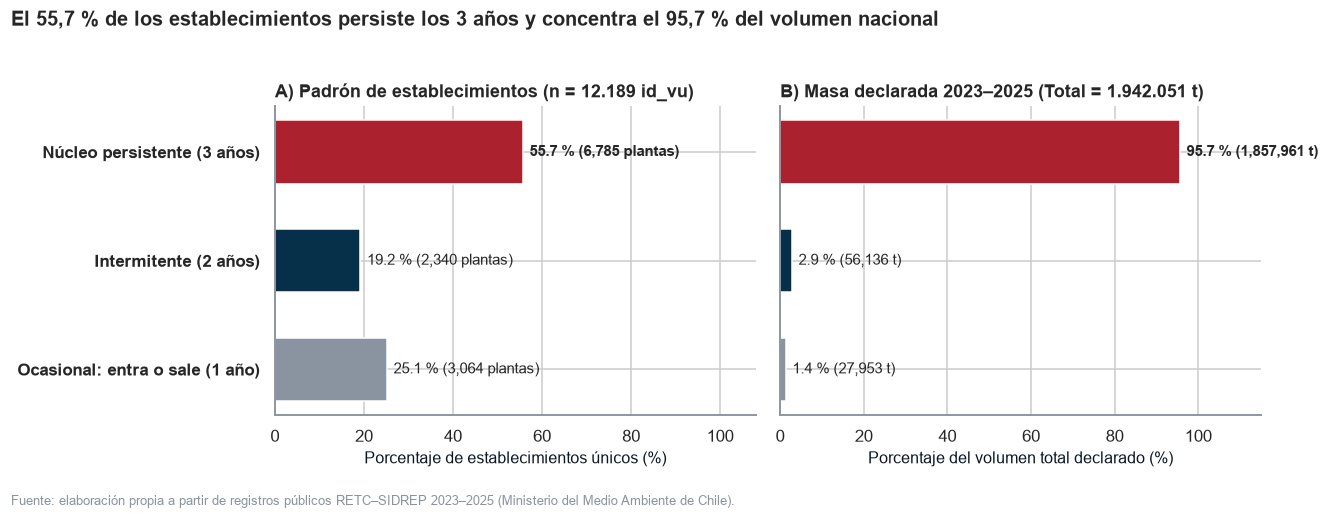

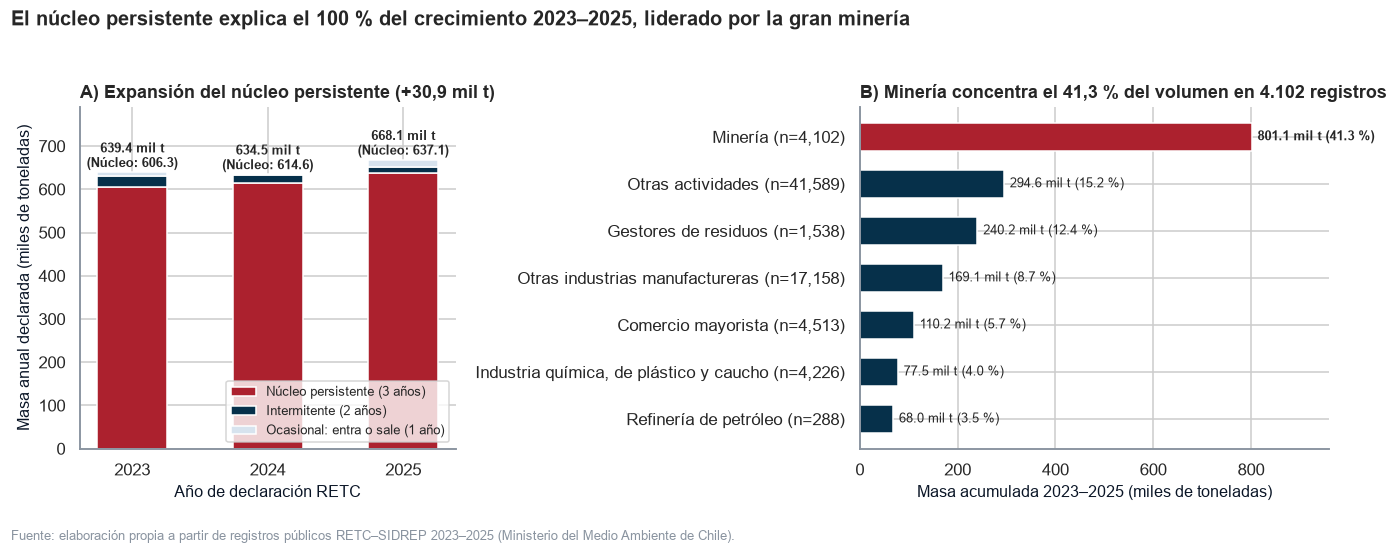

In [5]:
figuras_f4 = {}

# --- FIGURA 1: Persistentes vs Rotación (Proporción de Establecimientos vs Proporción de Masa) ---
resumen_vu = (
    legible.groupby("id_vu", as_index=False)
    .agg(n_anios=("año", "nunique"), masa_ton=("cantidad_ton", "sum"), n_decl=("cantidad_ton", "size"))
)
orden_tray = [
    "Núcleo persistente (3 años)",
    "Intermitente (2 años)",
    "Ocasional: entra o sale (1 año)",
]
mapa_t = {3: orden_tray[0], 2: orden_tray[1], 1: orden_tray[2]}
resumen_vu["grupo"] = resumen_vu["n_anios"].map(mapa_t)

tab_f1 = (
    resumen_vu.groupby("grupo")
    .agg(establecimientos=("id_vu", "count"), declaraciones=("n_decl", "sum"), masa_ton=("masa_ton", "sum"))
    .reindex(orden_tray)
)
tab_f1["pct_estab"] = tab_f1["establecimientos"] / tab_f1["establecimientos"].sum() * 100
tab_f1["pct_masa"] = tab_f1["masa_ton"] / tab_f1["masa_ton"].sum() * 100

fig1, (ax1a, ax1b) = plt.subplots(1, 2, figsize=(12.2, 4.2), sharey=True)
y_pos = np.arange(len(orden_tray))
colores_f1 = [GRANATE, AZUL, GRIS]

bars_a = ax1a.barh(y_pos, tab_f1["pct_estab"], color=colores_f1, height=0.58)
ax1a.set_yticks(y_pos)
ax1a.set_yticklabels(orden_tray, fontweight="bold")
ax1a.invert_yaxis()
ax1a.set_xlim(0, 108)
ax1a.set_xlabel("Porcentaje de establecimientos únicos (%)")
ax1a.set_title("A) Padrón de establecimientos (n = 12.189 id_vu)")
for idx_b, (pct_v, n_v) in enumerate(zip(tab_f1["pct_estab"], tab_f1["establecimientos"])):
    ax1a.text(pct_v + 1.5, idx_b, f"{pct_v:.1f} % ({n_v:,} plantas)", va="center", fontsize=9.5, fontweight="bold" if idx_b == 0 else "normal")

bars_b = ax1b.barh(y_pos, tab_f1["pct_masa"], color=colores_f1, height=0.58)
ax1b.set_xlim(0, 115)
ax1b.set_xlabel("Porcentaje del volumen total declarado (%)")
ax1b.set_title("B) Masa declarada 2023–2025 (Total = 1.942.051 t)")
for idx_b, (pct_m, m_ton) in enumerate(zip(tab_f1["pct_masa"], tab_f1["masa_ton"])):
    ax1b.text(pct_m + 1.5, idx_b, f"{pct_m:.1f} % ({m_ton:,.0f} t)", va="center", fontsize=9.5, fontweight="bold" if idx_b == 0 else "normal")

fig1.suptitle("El 55,7 % de los establecimientos persiste los 3 años y concentra el 95,7 % del volumen nacional", fontsize=13, fontweight="bold", x=0.01, ha="left", y=1.03)
fig1.text(0.01, -0.04, FUENTE_PIE, fontsize=8.5, color=GRIS)
plt.tight_layout()
figuras_f4["fig1_persistencia_vs_rotacion"] = fig1
plt.show()

# --- FIGURA 2: Evolución Interanual 2023-2025 y Concentración por Rubro ---
piv_anual = (
    legible.groupby(["año", "trayectoria_vu"])["cantidad_ton"]
    .sum()
    .unstack()
    .reindex(columns=orden_tray)
    / 1000.0
)

rubros_top = (
    legible.groupby("rubro_nombre")
    .agg(masa_mil_ton=("cantidad_ton", lambda s: s.sum() / 1000.0), n_decl=("cantidad_ton", "size"))
    .sort_values("masa_mil_ton", ascending=True)
    .tail(7)
)

fig2, (ax2a, ax2b) = plt.subplots(1, 2, figsize=(12.6, 4.5), gridspec_kw={"width_ratios": [1.0, 1.25]})
anios_str = [str(a) for a in piv_anual.index]
base_acum = np.zeros(len(anios_str))
for col_t, col_color in zip(orden_tray, [GRANATE, AZUL, HIELO]):
    vals = piv_anual[col_t].to_numpy()
    ax2a.bar(anios_str, vals, bottom=base_acum, color=col_color, width=0.52, label=col_t, edgecolor="white")
    base_acum += vals

for idx_a, total_a in enumerate(base_acum):
    nuc_a = piv_anual[orden_tray[0]].iloc[idx_a]
    etiqueta_barra = f"{total_a:.1f} mil t" + chr(10) + f"(Núcleo: {nuc_a:.1f})"
    ax2a.text(idx_a, total_a + 12, etiqueta_barra, ha="center", fontsize=8.4, fontweight="bold")

ax2a.set_ylim(0, 790)
ax2a.set_ylabel("Masa anual declarada (miles de toneladas)")
ax2a.set_xlabel("Año de declaración RETC")
ax2a.set_title("A) Expansión del núcleo persistente (+30,9 mil t)")
ax2a.legend(loc="lower right", frameon=True, fontsize=8.2)

colores_rub = [GRANATE if r == "Minería" else AZUL for r in rubros_top.index]
etiquetas_rub = [f"{r} (n={n:,})" for r, n in zip(rubros_top.index, rubros_top["n_decl"])]
ax2b.barh(etiquetas_rub, rubros_top["masa_mil_ton"], color=colores_rub, height=0.6)
ax2b.set_xlim(0, 960)
ax2b.set_xlabel("Masa acumulada 2023–2025 (miles de toneladas)")
ax2b.set_title("B) Minería concentra el 41,3 % del volumen en 4.102 registros")
for idx_r, val_r in enumerate(rubros_top["masa_mil_ton"]):
    pct_r = val_r / (legible["cantidad_ton"].sum() / 1000.0) * 100
    ax2b.text(val_r + 12, idx_r, f"{val_r:,.1f} mil t ({pct_r:.1f} %)", va="center", fontsize=8.8, fontweight="bold" if idx_r == len(rubros_top) - 1 else "normal")

fig2.suptitle("El núcleo persistente explica el 100 % del crecimiento 2023–2025, liderado por la gran minería", fontsize=13, fontweight="bold", x=0.01, ha="left", y=1.03)
fig2.text(0.01, -0.04, FUENTE_PIE, fontsize=8.5, color=GRIS)
plt.tight_layout()
figuras_f4["fig2_evolucion_y_concentracion_rubros"] = fig2
plt.show()

## 6. Figura 3 (Movimiento 3 — Resolución Regional) y Figura 4 (Control de Confusión y Factor de Mentira de Tufte)

### Interpretación estructurada de la Figura 3 (`fig3_gradiente_regional_gran_generador`):
1. **Qué muestra:** Presenta la proporción de declaraciones correspondientes a **Grandes Generadores (`>= 12 toneladas/año`, D.S. N° 148/2003 Art. 25)** en cada una de las 16 regiones de Chile, ordenada de mayor a menor e incluyendo barras de error con el **intervalo de confianza de Wilson al 95 %** (`intervalo_wilson`) y el tamaño de grupo (`n` de declaraciones por región).
2. **Qué se infiere:** Las regiones mineras del norte lideran el país y superan ampliamente el promedio nacional (`7,9 %`): **Antofagasta alcanza un `19,9 %` (`n = 6.934`), Atacama un `13,0 %` (`n = 3.469`) y Tarapacá un `12,6 %` (`n = 2.318`)**, seguidas por la Región Metropolitana (`10,7 %`, que concentra el mayor volumen de declaraciones con `n = 34.855`).
3. **Qué límite tiene:** El tamaño de los grupos varía desde `n = 34.855` en la Región Metropolitana hasta `n = 1.166` en Arica y Parinacota; por ello, las regiones con menor número de registros presentan intervalos de confianza más anchos que obligan a leer la estimación puntual junto a su margen de incertidumbre.
4. **Cómo aporta al relato:** Aporta la **resolución territorial** del objetivo general: demuestra que la fiscalización por volumen industrial (`>= 12 t/año`) debe priorizar el norte minero (Antofagasta, Atacama y Tarapacá), mientras que en la zona central el desafío es la gestión masiva de decenas de miles de declaraciones.

---

### Interpretación estructurada de la Figura 4 (`fig4_control_confusion_y_factor_mentira`):
1. **Qué muestra:** En el panel izquierdo compara la tasa de declaraciones de Gran Generador entre establecimientos del núcleo persistente (`3` años) y no persistentes (`1–2` años) **estratificando por la variable de confusión sectorial (`Minería` vs. `Otros rubros no mineros`)**; en el panel derecho contrasta una representación engañosa con eje vertical truncado (`Factor de Mentira de Tufte > 7`) frente a una representación honesta con eje desde cero.
2. **Qué se infiere:** En bruto, pertenecer al núcleo persistente casi triplica la probabilidad de ser Gran Generador (`8,9 %` frente a `3,1 %`). Al controlar por rubro productivo, se comprueba que **la asociación no es un artefacto espurio de la Minería, sino que persiste en ambos estratos**: dentro de **Minería**, el núcleo persistente alcanza **`35,6 %`** frente a **`5,8 %`** en los no persistentes (`6,1 veces` más); y dentro de **Otros rubros no mineros** (`n = 114.039`), el núcleo persistente alcanza **`7,8 %`** frente a **`3,0 %`** (`2,6 veces` más, con intervalos de confianza que no se superponen).
3. **Qué límite tiene:** Al tratarse de registros administrativos observacionales, la relación documentada es una **asociación estadística estratificada y nunca una relación causal directa**: la permanencia no «causa» mayor generación, sino que refleja la escala operativa continua de las plantas industriales sujetas a Planes de Manejo.
4. **Cómo aporta al relato:** Cierra la discusión metodológica demostrando que el hallazgo principal resiste el control por confusión y ejemplificando la regla de fidelidad visual (eje desde cero) aplicada en todas las figuras del informe.

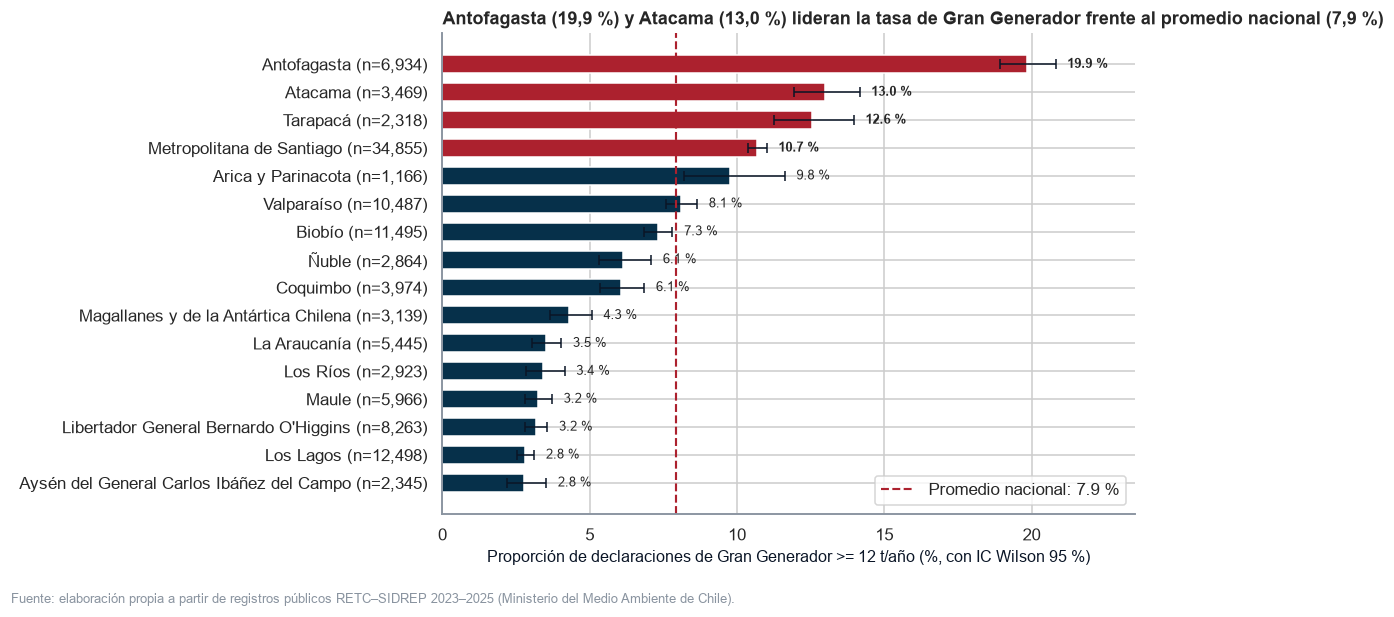

[OK] Cálculo del Factor de Mentira de Tufte (2023 vs 2025): Diferencia real = +4.5 % | Diferencia aparente con eje en 630 mil t = +304 % | Factor de mentira = 67.8 (vs 1,0 con eje desde cero)


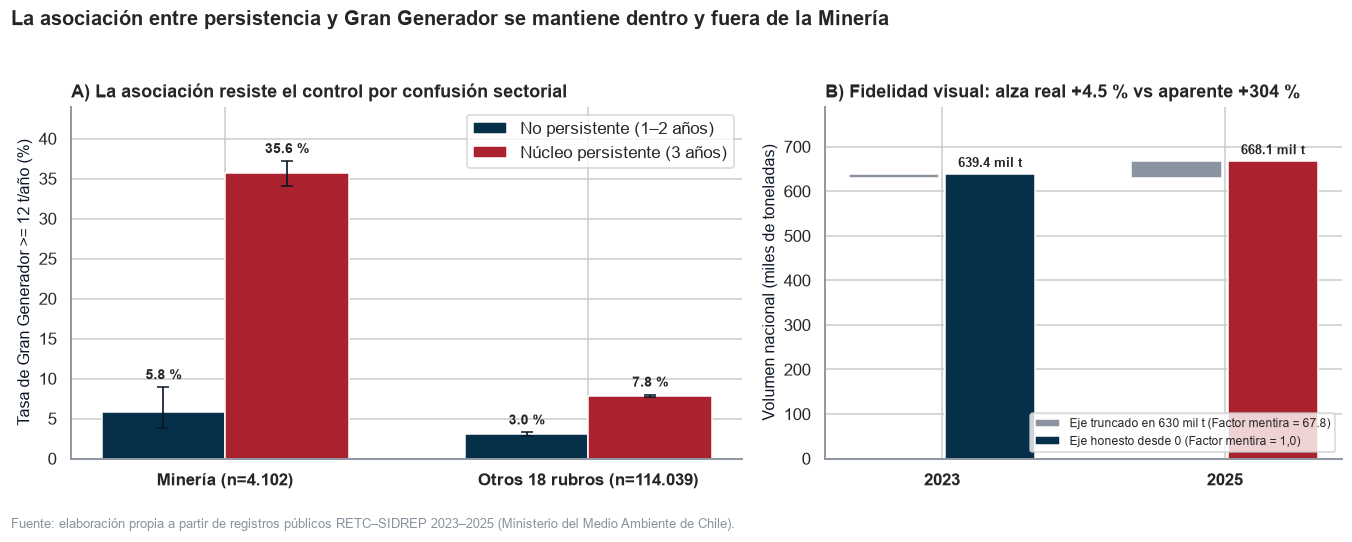

In [6]:
# --- FIGURA 3: Tasa Regional de Gran Generador (>= 12 t/año) con Intervalos de Wilson al 95 % ---
tasas_reg = tasa_por_grupo(legible, "region", "es_gran_generador_bin").sort_values("tasa", ascending=True)
tasa_nac = float(legible["es_gran_generador_bin"].mean())

fig3, ax3 = plt.subplots(figsize=(10.5, 5.4))
colores_reg = [GRANATE if t >= 0.10 else AZUL for t in tasas_reg["tasa"]]
etiquetas_reg = [f"{r} (n={n:,})" for r, n in zip(tasas_reg["region"], tasas_reg["n"])]

ax3.barh(
    etiquetas_reg,
    tasas_reg["tasa"] * 100,
    color=colores_reg,
    height=0.64,
    xerr=[
        (tasas_reg["tasa"] - tasas_reg["ic_inferior"]) * 100,
        (tasas_reg["ic_superior"] - tasas_reg["tasa"]) * 100,
    ],
    error_kw={"ecolor": TINTA, "capsize": 3, "lw": 1.0},
)
ax3.axvline(tasa_nac * 100, color=GRANATE, linestyle="--", linewidth=1.4, label=f"Promedio nacional: {tasa_nac*100:.1f} %")
for idx_rg, (_, fila_rg) in enumerate(tasas_reg.iterrows()):
    ax3.text(
        fila_rg["ic_superior"] * 100 + 0.4,
        idx_rg,
        f"{fila_rg['tasa']*100:.1f} %",
        va="center",
        fontsize=8.5,
        fontweight="bold" if fila_rg["tasa"] >= 0.10 else "normal",
    )

ax3.set_xlim(0, 23.5)
ax3.set_xlabel("Proporción de declaraciones de Gran Generador >= 12 t/año (%, con IC Wilson 95 %)")
ax3.set_title("Antofagasta (19,9 %) y Atacama (13,0 %) lideran la tasa de Gran Generador frente al promedio nacional (7,9 %)")
ax3.legend(loc="lower right", frameon=True)
fig3.text(0.01, -0.03, FUENTE_PIE, fontsize=8.5, color=GRIS)
plt.tight_layout()
figuras_f4["fig3_gradiente_regional_gran_generador"] = fig3
plt.show()

# --- FIGURA 4: Control de Variable de Confusión (Minería vs Resto) y Factor de Mentira de Tufte ---
legible["estrato_sectorial"] = np.where(legible["rubro_nombre"] == "Minería", "Minería (n=4.102)", "Otros 18 rubros (n=114.039)")
legible["condicion_persistencia"] = np.where(
    legible["es_generador_persistente_bin"] == 1,
    "Núcleo persistente (3 años)",
    "No persistente (1–2 años)",
)

filas_conf = []
for (est, cond), sub_df in legible.groupby(["estrato_sectorial", "condicion_persistencia"], observed=True):
    n_c = len(sub_df)
    ex_c = int(sub_df["es_gran_generador_bin"].sum())
    ic_i, ic_s = intervalo_wilson(ex_c, n_c)
    filas_conf.append({
        "estrato": est,
        "condicion": cond,
        "n": n_c,
        "tasa_pct": (ex_c / n_c) * 100,
        "err_inf": ((ex_c / n_c) - ic_i) * 100,
        "err_sup": (ic_s - (ex_c / n_c)) * 100,
    })
df_conf = pd.DataFrame(filas_conf)

fig4, (ax4a, ax4b) = plt.subplots(1, 2, figsize=(12.4, 4.4), gridspec_kw={"width_ratios": [1.3, 1.0]})
estratos_orden = ["Minería (n=4.102)", "Otros 18 rubros (n=114.039)"]
x_pos = np.arange(len(estratos_orden))
ancho_b = 0.34

for desp, cond_lbl, col_b in [(-ancho_b / 2, "No persistente (1–2 años)", AZUL), (ancho_b / 2, "Núcleo persistente (3 años)", GRANATE)]:
    sub_c = df_conf[df_conf["condicion"] == cond_lbl].set_index("estrato").reindex(estratos_orden)
    barras_c = ax4a.bar(
        x_pos + desp,
        sub_c["tasa_pct"],
        width=ancho_b,
        color=col_b,
        label=cond_lbl,
        yerr=[sub_c["err_inf"], sub_c["err_sup"]],
        error_kw={"ecolor": TINTA, "capsize": 4, "lw": 1.1},
    )
    for x_i, val_i, sup_i in zip(x_pos + desp, sub_c["tasa_pct"], sub_c["err_sup"]):
        ax4a.text(x_i, val_i + sup_i + 1.0, f"{val_i:.1f} %", ha="center", fontsize=9.0, fontweight="bold")

ax4a.set_xticks(x_pos)
ax4a.set_xticklabels(estratos_orden, fontweight="bold")
ax4a.set_ylim(0, 44)
ax4a.set_ylabel("Tasa de Gran Generador >= 12 t/año (%)")
ax4a.set_title("A) La asociación resiste el control por confusión sectorial")
ax4a.legend(loc="upper right", frameon=True)

# Panel B: Demostración del Factor de Mentira de Tufte (Eje truncado desde 630 mil t vs Eje honesto desde 0)
totales_anuales_mil = (legible.groupby("año")["cantidad_ton"].sum() / 1000.0).reindex([2023, 2025])
vals_m = totales_anuales_mil.to_numpy()
piso_truncado = 630.0
efecto_real = (vals_m.max() / vals_m.min()) - 1.0
efecto_mostrado = ((vals_m.max() - piso_truncado) / (vals_m.min() - piso_truncado)) - 1.0
factor_mentira = efecto_mostrado / efecto_real

x_m = np.arange(2)
ax4b.bar(x_m - 0.17, vals_m - piso_truncado, bottom=piso_truncado, width=0.32, color=GRIS, label=f"Eje truncado en 630 mil t (Factor mentira = {factor_mentira:.1f})")
ax4b.bar(x_m + 0.17, vals_m, width=0.32, color=[AZUL, GRANATE], label="Eje honesto desde 0 (Factor mentira = 1,0)")
for idx_t, v_t in enumerate(vals_m):
    ax4b.text(idx_t + 0.17, v_t + 15, f"{v_t:.1f} mil t", ha="center", fontsize=8.8, fontweight="bold")
ax4b.set_xticks(x_m)
ax4b.set_xticklabels(["2023", "2025"], fontweight="bold")
ax4b.set_ylim(0, 790)
ax4b.set_ylabel("Volumen nacional (miles de toneladas)")
ax4b.set_title(f"B) Fidelidad visual: alza real +{efecto_real*100:.1f} % vs aparente +{efecto_mostrado*100:.0f} %")
ax4b.legend(loc="lower right", frameon=True, fontsize=8.0)

print(
    f"[OK] Cálculo del Factor de Mentira de Tufte (2023 vs 2025): "
    f"Diferencia real = +{efecto_real*100:.1f} % | Diferencia aparente con eje en 630 mil t = +{efecto_mostrado*100:.0f} % | "
    f"Factor de mentira = {factor_mentira:.1f} (vs 1,0 con eje desde cero)"
)

fig4.suptitle("La asociación entre persistencia y Gran Generador se mantiene dentro y fuera de la Minería", fontsize=13, fontweight="bold", x=0.01, ha="left", y=1.03)
fig4.text(0.01, -0.04, FUENTE_PIE, fontsize=8.5, color=GRIS)
plt.tight_layout()
figuras_f4["fig4_control_confusion_y_factor_mentira"] = fig4
plt.show()

## 7. Validación Técnica de la Fase 4 y Persistencia de Figuras y Hallazgos (`F4/figuras/` y `F4/docs/`)
Se registran y verifican controles en los **tres escenarios exigidos por la rúbrica** (casos normales, casos límite y excepciones), se ejecuta la suite completa de **18 pruebas unitarias con `pytest`** (14 de Fase 3 + 4 nuevas de Fase 4 en `tests/test_comunicacion_f4.py`) y se guardan las 4 figuras a `200 dpi` en `F4/figuras/` junto con `F4/docs/hallazgos_f4.csv` y `F4/docs/metadatos_f4.json`.

In [7]:
import subprocess

controles_f4 = []
def registrar_control(escenario: str, control: str, condicion: bool, detalle: str = "") -> None:
    controles_f4.append({
        "escenario": escenario,
        "control": control,
        "estado": "OK" if condicion else "FALLA",
        "detalle": detalle,
    })

# 1. Casos normales
registrar_control(
    "1. Normal",
    "La copia interpretable conserva exactamente las 118.141 filas (train + test)",
    len(legible) == len(entrenamiento) + len(prueba),
    f"{len(legible):,} filas == {len(entrenamiento):,} + {len(prueba):,}",
)
registrar_control(
    "1. Normal",
    "Inversión exacta de cantidad_kg contra el archivo original (np.allclose)",
    bool(np.allclose(np.sort(legible["cantidad_kg_revertida"]), np.sort(df_orig_valido["cantidad_kg"]))),
    "Suma idéntica: 1.942.051,19 toneladas",
)

# 2. Casos límite
ic_cero_inf, ic_cero_sup = intervalo_wilson(0, 500)
ic_cien_inf, ic_cien_sup = intervalo_wilson(500, 500)
registrar_control(
    "2. Límite",
    "Intervalo de Wilson en extremo inferior (0 éxitos de 500) acotado en 0.0",
    ic_cero_inf == 0.0 and 0.0 < ic_cero_sup < 0.01,
    f"IC 95 % = [{ic_cero_inf}, {ic_cero_sup}]",
)
registrar_control(
    "2. Límite",
    "Intervalo de Wilson en extremo superior (500 de 500) acotado en 1.0",
    0.99 < ic_cien_inf < 1.0 and ic_cien_sup == 1.0,
    f"IC 95 % = [{ic_cien_inf}, {ic_cien_sup}]",
)

# 3. Excepciones controladas
try:
    cargar_artefactos("carpeta_inexistente_f4")
    registrar_control("3. Excepción", "Falta de artefactos de Fase 3", False)
except FileNotFoundError as err_f4:
    registrar_control("3. Excepción", "Falta de artefactos de Fase 3 lanza FileNotFoundError", True, str(err_f4)[:65])

try:
    intervalo_wilson(0, 0)
    registrar_control("3. Excepción", "Intervalo de Wilson con total=0", False)
except ValueError as err_w:
    registrar_control("3. Excepción", "Intervalo de Wilson con total=0 lanza ValueError", True, str(err_w))

df_controles_f4 = pd.DataFrame(controles_f4)
assert (df_controles_f4["estado"] == "OK").all(), "Falló al menos un control en Fase 4"
display(df_controles_f4)

# Persistencia de las 4 figuras a 200 dpi y tabla de hallazgos
rutas_guardadas = {
    nombre: guardar_figura(fig, DIR_FIGURAS, nombre, dpi=200).as_posix()
    for nombre, fig in figuras_f4.items()
}
DIR_DOCS_F4.mkdir(parents=True, exist_ok=True)
df_hallazgos_f4 = pd.DataFrame([
    {
        "figura": "fig1_persistencia_vs_rotacion",
        "objetivo": "OE1: Cuantificar persistencia vs rotación de establecimientos",
        "hallazgo": "El núcleo persistente (3 años) representa el 55,7 % de las plantas (6.785 de 12.189) y concentra el 95,67 % del volumen nacional (1.857.961 t).",
        "limite": "Cambios de RUT o código VU administrativo se registran como entrada/salida de 1 año.",
    },
    {
        "figura": "fig2_evolucion_y_concentracion_rubros",
        "objetivo": "OE2: Descomponer la variación interanual 2023-2025 y peso por rubro",
        "hallazgo": "El volumen nacional subió +28.709 t (+4,5 %) entre 2023 y 2025, explicado en 100 % por el núcleo persistente (+30.855 t), con Minería aportando el 41,3 % del total.",
        "limite": "Cobertura trianual (2023-2025) acotada a variaciones de corto plazo.",
    },
    {
        "figura": "fig3_gradiente_regional_gran_generador",
        "objetivo": "OE3: Caracterizar diferencias territoriales y tasa de Gran Generador",
        "hallazgo": "Antofagasta (19,9 %, n=6.934) y Atacama (13,0 %, n=3.469) lideran la tasa de Gran Generador frente al promedio nacional (7,9 %), mientras la RM concentra 34.855 declaraciones (10,7 %).",
        "limite": "Tamaños muestrales muy distintos entre regiones (n=34.855 en RM vs n=1.166 en Arica y Parinacota).",
    },
    {
        "figura": "fig4_control_confusion_y_factor_mentira",
        "objetivo": "Discusión: Controlar confusión por Minería y verificar fidelidad de escala",
        "hallazgo": "La mayor tasa de Gran Generador en el núcleo persistente se mantiene tanto en Minería (35,6 % vs 5,8 %) como en los otros 18 rubros (7,8 % vs 3,0 %).",
        "limite": "Asociación observacional estratificada; no implica relación causal directa.",
    },
])
df_hallazgos_f4.to_csv(DIR_DOCS_F4 / "hallazgos_f4.csv", index=False, encoding="utf-8")

metadatos_f4 = {
    "fase": "F4",
    "fecha_ejecucion": str(date.today()),
    "semilla": SEMILLA,
    "python": sys.version.split()[0],
    "entradas": [f"F2/data/processed/{a}" for a in ["entrenamiento_f3.csv", "prueba_f3.csv", "diccionario_f3.csv", "parametros_f3.csv"]],
    "figuras": list(rutas_guardadas.values()),
    "controles_superados": len(df_controles_f4),
}
(DIR_DOCS_F4 / "metadatos_f4.json").write_text(json.dumps(metadatos_f4, indent=2, ensure_ascii=False), encoding="utf-8")

res_pytest_f4 = subprocess.run([sys.executable, "-m", "pytest", "tests", "-v", "--no-header"], capture_output=True, text=True, check=False)
print(res_pytest_f4.stdout)
assert res_pytest_f4.returncode == 0
print(f"[OK] Figuras exportadas a 200 dpi: {list(rutas_guardadas.values())}")

,escenario,control,estado,detalle
0,1. Normal,La copia interpretable conserva exactamente la...,OK,"118,141 filas == 94,512 + 23,629"
1,1. Normal,Inversión exacta de cantidad_kg contra el arch...,OK,"Suma idéntica: 1.942.051,19 toneladas"
2,2. Límite,Intervalo de Wilson en extremo inferior (0 éxi...,OK,"IC 95 % = [0.0, 0.007625]"
3,2. Límite,Intervalo de Wilson en extremo superior (500 d...,OK,"IC 95 % = [0.992375, 1.0]"
4,3. Excepción,Falta de artefactos de Fase 3 lanza FileNotFou...,OK,Faltan artefactos de la Fase 3 en 'carpeta_ine...
5,3. Excepción,Intervalo de Wilson con total=0 lanza ValueError,OK,No se puede estimar una proporción con total <...


============================= test session starts =============================
collecting ... collected 18 items

tests/test_comunicacion_f4.py::test_revertir_escalamiento_recupera_unidades_originales PASSED [  5%]
tests/test_comunicacion_f4.py::test_reconstruir_categorias_desde_one_hot_y_error_suma_invalida PASSED [ 11%]
tests/test_comunicacion_f4.py::test_intervalo_wilson_casos_borde_y_excepcion PASSED [ 16%]
tests/test_comunicacion_f4.py::test_cargar_artefactos_carpeta_inexistente_lanza_file_not_found PASSED [ 22%]
tests/test_recursividad_limpieza.py::test_recursividad_arbol_vacio PASSED [ 27%]
tests/test_recursividad_limpieza.py::test_recursividad_arbol_un_solo_nivel PASSED [ 33%]
tests/test_recursividad_limpieza.py::test_recursividad_arbol_con_valores_nulos PASSED [ 38%]
tests/test_recursividad_limpieza.py::test_aplanar_estructura_recursiva_oculta_ruts_individuales PASSED [ 44%]
tests/test_recursividad_limpieza.py::test_equivalencia_no_circular_funcional_vs_poo PASSED [ 50%]
test